In [1]:
!git clone -b megha-work https://github.com/meghagangal362015/cmpe257-early-reading-prediction.git
%cd cmpe257-early-reading-prediction

Cloning into 'cmpe257-early-reading-prediction'...
remote: Enumerating objects: 51, done.
remote: Counting objects: 100% (51/51), done.
remote: Compressing objects: 100% (39/39), done.
remote: Total 51 (delta 7), reused 40 (delta 5), pack-reused 0 (from 0)
Receiving objects: 100% (51/51), 835.08 KiB | 14.40 MiB/s, done.
Resolving deltas: 100% (7/7), done.
/content/cmpe257-early-reading-prediction


In [4]:
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report

train = pd.read_csv("data/processed/train.csv")
validation = pd.read_csv("data/processed/validation.csv")
test = pd.read_csv("data/processed/test.csv")

In [5]:
drop_columns = [
    "StuID",
    "SchlID",
    "TeachID",
    "split",
    "RMwidRS_target",
    "RMwdaRS_target",
    "SAtoS_target",
    "grp_rate",
    "rcmistot",
    "gnrl_fid",
    "Tier2MinRd"
]

def clean_features(df):
    columns_to_drop = []

    for column in df.columns:
        if (
            column in drop_columns
            or "_spring" in column
            or "_gain" in column
            or "_mid" in column
        ):
            columns_to_drop.append(column)

    return df.drop(columns=columns_to_drop, errors="ignore")

In [6]:
def prepare_target(target):
    train_target = train.dropna(subset=[target])
    validation_target = validation.dropna(subset=[target])
    test_target = test.dropna(subset=[target])

    X_train = clean_features(train_target.drop(columns=[target]))
    X_val = clean_features(validation_target.drop(columns=[target]))
    X_test = clean_features(test_target.drop(columns=[target]))

    y_train = train_target[target].astype(int)
    y_val = validation_target[target].astype(int)
    y_test = test_target[target].astype(int)

    numeric_columns = X_train.select_dtypes(include=["number"]).columns
    categorical_columns = X_train.select_dtypes(exclude=["number"]).columns

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numeric",
                SimpleImputer(strategy="median"),
                numeric_columns
            ),
            (
                "categorical",
                Pipeline([
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("encoder", OneHotEncoder(handle_unknown="ignore"))
                ]),
                categorical_columns
            )
        ]
    )

    X_train_processed = preprocessor.fit_transform(X_train)
    X_val_processed = preprocessor.transform(X_val)
    X_test_processed = preprocessor.transform(X_test)

    return (
        X_train_processed,
        X_val_processed,
        X_test_processed,
        y_train,
        y_val,
        y_test,
        preprocessor
    )

In [7]:
word_id_data = prepare_target("RMwidRS_target")
word_attack_data = prepare_target("RMwdaRS_target")

print("Word Identification training shape:", word_id_data[0].shape)
print("Word Attack training shape:", word_attack_data[0].shape)

Word Identification training shape: (700, 26)
Word Attack training shape: (700, 26)


In [8]:
datasets = {
    "Word Identification": word_id_data,
    "Word Attack": word_attack_data
}

models = {}
results = []

for target_name, data in datasets.items():
    (
        X_train_processed,
        X_val_processed,
        X_test_processed,
        y_train,
        y_val,
        y_test,
        preprocessor
    ) = data

    model = RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )

    model.fit(X_train_processed, y_train)
    models[target_name] = model

    test_predictions = model.predict(X_test_processed)
    test_probabilities = model.predict_proba(X_test_processed)[:, 1]

    auc = roc_auc_score(y_test, test_probabilities)
    accuracy = accuracy_score(y_test, test_predictions)

    results.append({
        "Target": target_name,
        "Model": "Random Forest",
        "Test AUC": auc,
        "Test Accuracy": accuracy
    })

    print(f"\n{target_name}")
    print("Test AUC:", round(auc, 4))
    print("Test Accuracy:", round(accuracy, 4))
    print(classification_report(y_test, test_predictions))

results_df = pd.DataFrame(results)
results_df


Word Identification
Test AUC: 0.5252
Test Accuracy: 0.5905
              precision    recall  f1-score   support

           0       0.46      0.40      0.43        40
           1       0.66      0.71      0.68        65

    accuracy                           0.59       105
   macro avg       0.56      0.55      0.55       105
weighted avg       0.58      0.59      0.58       105


Word Attack
Test AUC: 0.5018
Test Accuracy: 0.6
              precision    recall  f1-score   support

           0       0.36      0.13      0.19        38
           1       0.64      0.87      0.73        67

    accuracy                           0.60       105
   macro avg       0.50      0.50      0.46       105
weighted avg       0.54      0.60      0.54       105



,Target,Model,Test AUC,Test Accuracy
0,Word Identification,Random Forest,0.525192,0.590476
1,Word Attack,Random Forest,0.501767,0.600000


In [9]:
# Random Forest validation results

for target_name, data in datasets.items():
    (
        X_train_processed,
        X_val_processed,
        X_test_processed,
        y_train,
        y_val,
        y_test,
        preprocessor
    ) = data

    model = models[target_name]

    val_predictions = model.predict(X_val_processed)
    val_probabilities = model.predict_proba(X_val_processed)[:, 1]

    validation_auc = roc_auc_score(
        y_val,
        val_probabilities
    )

    validation_accuracy = accuracy_score(
        y_val,
        val_predictions
    )

    print(target_name)
    print("Validation AUC:",
          round(validation_auc, 4))
    print("Validation Accuracy:",
          round(validation_accuracy, 4))
    print()

Word Identification
Validation AUC: 0.6807
Validation Accuracy: 0.6241

Word Attack
Validation AUC: 0.632
Validation Accuracy: 0.5745



In [10]:
from sklearn.model_selection import ParameterGrid

parameter_grid = {
    "n_estimators": [200, 400],
    "max_depth": [None, 5, 10],
    "min_samples_leaf": [1, 2, 5]
}

best_models = {}
best_scores = {}
best_parameters = {}

for target_name, data in datasets.items():

    (
        X_train_processed,
        X_val_processed,
        X_test_processed,
        y_train,
        y_val,
        y_test,
        preprocessor
    ) = data

    best_auc = 0
    best_model = None
    best_params = None

    for parameters in ParameterGrid(parameter_grid):

        model = RandomForestClassifier(
            **parameters,
            random_state=42,
            class_weight="balanced",
            n_jobs=-1
        )

        model.fit(X_train_processed, y_train)

        val_probabilities = model.predict_proba(
            X_val_processed
        )[:, 1]

        val_auc = roc_auc_score(
            y_val,
            val_probabilities
        )

        if val_auc > best_auc:
            best_auc = val_auc
            best_model = model
            best_params = parameters

    best_models[target_name] = best_model
    best_scores[target_name] = best_auc
    best_parameters[target_name] = best_params

    print(target_name)
    print("Best validation AUC:", round(best_auc, 4))
    print("Best parameters:", best_params)
    print()

Word Identification
Best validation AUC: 0.7215
Best parameters: {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 400}

Word Attack
Best validation AUC: 0.6595
Best parameters: {'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 200}



In [11]:
final_results = []

for target_name, data in datasets.items():

    (
        X_train_processed,
        X_val_processed,
        X_test_processed,
        y_train,
        y_val,
        y_test,
        preprocessor
    ) = data

    best_model = best_models[target_name]

    test_predictions = best_model.predict(X_test_processed)
    test_probabilities = best_model.predict_proba(
        X_test_processed
    )[:, 1]

    test_auc = roc_auc_score(
        y_test,
        test_probabilities
    )

    test_accuracy = accuracy_score(
        y_test,
        test_predictions
    )

    final_results.append({
        "Target": target_name,
        "Model": "Tuned Random Forest",
        "Validation AUC": best_scores[target_name],
        "Test AUC": test_auc,
        "Test Accuracy": test_accuracy
    })

    print(target_name)
    print("Final Test AUC:", round(test_auc, 4))
    print("Final Test Accuracy:", round(test_accuracy, 4))
    print(classification_report(y_test, test_predictions))
    print()

final_results_df = pd.DataFrame(final_results)
final_results_df

Word Identification
Final Test AUC: 0.5277
Final Test Accuracy: 0.6
              precision    recall  f1-score   support

           0       0.47      0.42      0.45        40
           1       0.67      0.71      0.69        65

    accuracy                           0.60       105
   macro avg       0.57      0.57      0.57       105
weighted avg       0.59      0.60      0.60       105


Word Attack
Final Test AUC: 0.5558
Final Test Accuracy: 0.5905
              precision    recall  f1-score   support

           0       0.35      0.16      0.22        38
           1       0.64      0.84      0.72        67

    accuracy                           0.59       105
   macro avg       0.49      0.50      0.47       105
weighted avg       0.53      0.59      0.54       105




,Target,Model,Validation AUC,Test AUC,Test Accuracy
0,Word Identification,Tuned Random Forest,0.721529,0.527692,0.600000
1,Word Attack,Tuned Random Forest,0.659544,0.555774,0.590476



Top features for Word Identification


,Feature,Importance
16,numeric__RMwidRS,0.122577
20,numeric__Schl_Asian,0.082477
12,numeric__ORFwc,0.067804
11,numeric__NWFwrc,0.061815
17,numeric__RMwdaRS,0.057094
10,numeric__NWFcls,0.054885
6,numeric__Age1b,0.048567
21,numeric__Schl_Hispanic,0.048230
15,numeric__SAtoS,0.048145
23,numeric__Schl_White,0.046899


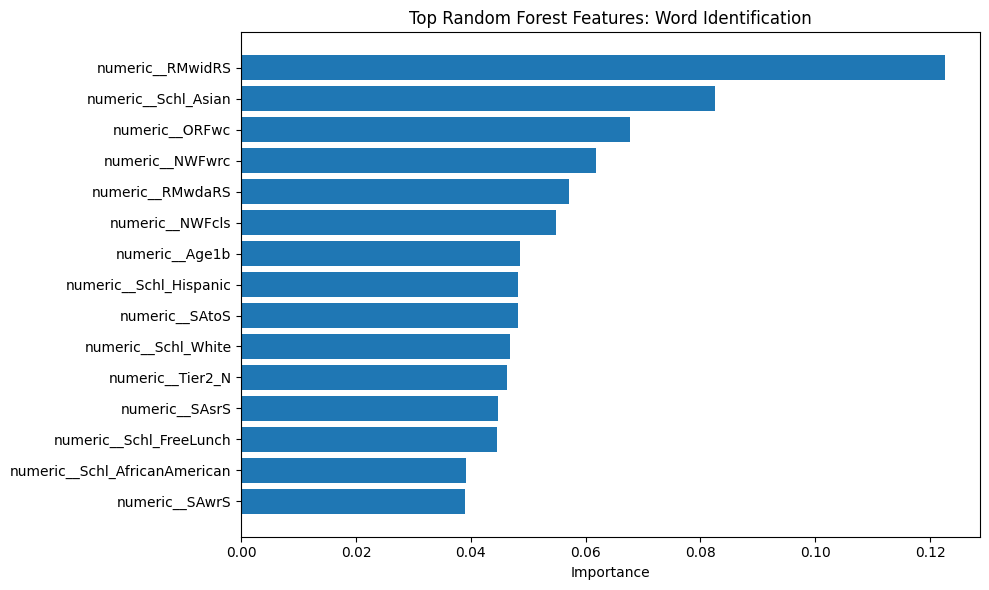


Top features for Word Attack


,Feature,Importance
17,numeric__RMwdaRS,0.079162
11,numeric__NWFwrc,0.069770
10,numeric__NWFcls,0.069153
6,numeric__Age1b,0.067259
16,numeric__RMwidRS,0.066906
13,numeric__SAwrS,0.059227
12,numeric__ORFwc,0.058253
15,numeric__SAtoS,0.057549
14,numeric__SAsrS,0.056606
9,numeric__TYearsTeaching,0.048711


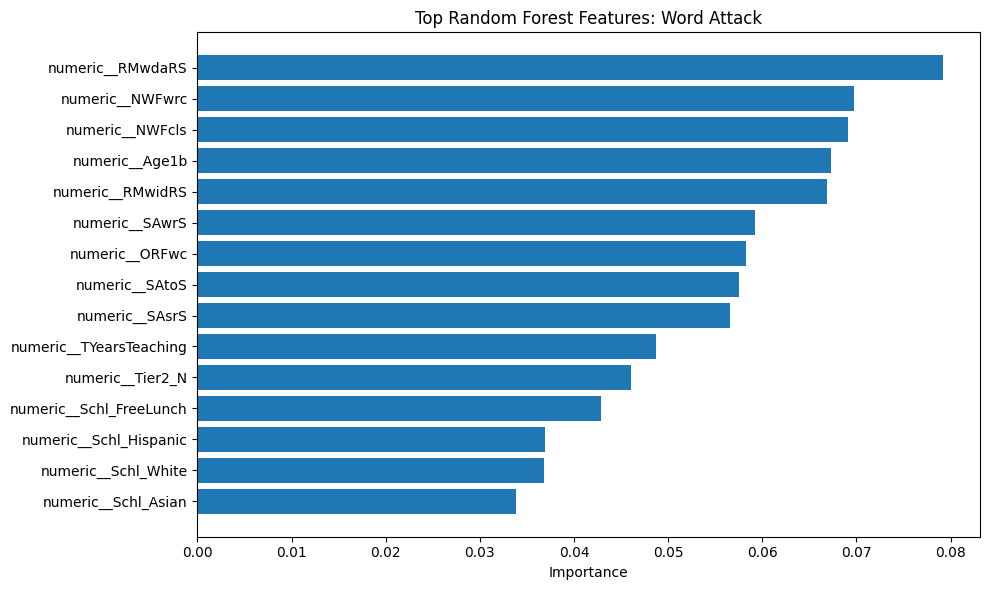

In [12]:
import matplotlib.pyplot as plt

for target_name, data in datasets.items():

    (
        X_train_processed,
        X_val_processed,
        X_test_processed,
        y_train,
        y_val,
        y_test,
        preprocessor
    ) = data

    model = best_models[target_name]

    feature_names = preprocessor.get_feature_names_out()
    importances = model.feature_importances_

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    }).sort_values(
        "Importance",
        ascending=False
    )

    print(f"\nTop features for {target_name}")
    display(importance_df.head(15))

    top_features = importance_df.head(15).sort_values(
        "Importance"
    )

    plt.figure(figsize=(10, 6))
    plt.barh(
        top_features["Feature"],
        top_features["Importance"]
    )
    plt.title(f"Top Random Forest Features: {target_name}")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()